In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch

p = print
d = display

p("PyTorch:", torch.__version__)
p("tarjeta:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
tarjeta: True


In [2]:
Carpeta_Proyecto = Path.cwd().parent
Carpeta_listos = Carpeta_Proyecto / "Dataset" / "M_Listos"
p(Carpeta_listos)

/home/Ian/prediccion_red/Dataset/M_Listos


In [3]:
df_dig_e = pd.read_csv(Carpeta_listos / "M_entre.csv", dtype=np.uint8)
df_dig_p = pd.read_csv(Carpeta_listos / "M_prueb.csv", dtype=np.uint8)
df_let_e = pd.read_csv(Carpeta_listos / "emnist_entrenamiento.csv", dtype=np.uint8)
df_let_p = pd.read_csv(Carpeta_listos / "emnist_prueba.csv", dtype=np.uint8)
df_ani = pd.read_csv(Carpeta_listos / "animales.csv", dtype=np.uint8)

p("Dígitos:", df_dig_e.shape, df_dig_p.shape)
p("Letras:", df_let_e.shape, df_let_p.shape)
p("Animales:", df_ani.shape)

Dígitos: (60000, 785) (10000, 785)
Letras: (112800, 785) (18800, 785)
Animales: (120000, 785)


### leer los nombres de las letras y de los animales

In [4]:
nombres_emnist = pd.read_csv(Carpeta_listos / "nombres_emnist.csv").iloc[:, 0].astype(str).tolist()
nombres_animales = pd.read_csv(Carpeta_listos / "nombres_animales.csv").iloc[:, 0].astype(str).tolist()

p("EMNIST:", len(nombres_emnist), nombres_emnist)
p("Animales:", len(nombres_animales), nombres_animales)

EMNIST: 47 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'd', 'e', 'f', 'g', 'h', 'n', 'q', 'r', 't']
Animales: 20 ['gato', 'perro', 'pez', 'pájaro', 'conejo', 'caballo', 'vaca', 'cerdo', 'elefante', 'jirafa', 'serpiente', 'araña', 'mariposa', 'pato', 'búho', 'rana', 'cangrejo', 'pulpo', 'tiburón', 'caracol']


### separar los nombres en dígitos, letras y animales

In [5]:
clases_digitos = [str(i) for i in range(10)]
clases_letras = nombres_emnist[10:]
clases_animales = nombres_animales

p("Dígitos:", len(clases_digitos))
p("Letras:", len(clases_letras))
p("Animales:", len(clases_animales))

Dígitos: 10
Letras: 37
Animales: 20


### juntar las 67 clases y darle un número a cada una

In [6]:
clases = clases_digitos + clases_letras + clases_animales
indice = {c: i for i, c in enumerate(clases)}

p("Total de clases:", len(clases))
p("Número de la A:", indice["A"])
p("Número del primer animal:", indice[clases_animales[0]])

Total de clases: 67
Número de la A: 10
Número del primer animal: 47


### separar imágenes y respuestas de los dígitos

In [7]:
X_dig_e = df_dig_e.drop(columns="respuesta").values
Y_dig_e = df_dig_e["respuesta"].values
X_dig_p = df_dig_p.drop(columns="respuesta").values
Y_dig_p = df_dig_p["respuesta"].values

p("Dígitos entrenamiento:", X_dig_e.shape, "| prueba:", X_dig_p.shape)
p("Respuestas:", np.unique(Y_dig_e))

Dígitos entrenamiento: (60000, 784) | prueba: (10000, 784)
Respuestas: [0 1 2 3 4 5 6 7 8 9]


### imágenes y respuestas de las letras

In [8]:
letras_e = df_let_e[df_let_e["respuesta"] >= 10]
letras_p = df_let_p[df_let_p["respuesta"] >= 10]

X_let_e = letras_e.drop(columns="respuesta").values
Y_let_e = letras_e["respuesta"].values
X_let_p = letras_p.drop(columns="respuesta").values
Y_let_p = letras_p["respuesta"].values

p("Letras entrenamiento:", X_let_e.shape, "| prueba:", X_let_p.shape)
p("Respuestas: de", Y_let_e.min(), "a", Y_let_e.max())

Letras entrenamiento: (88800, 784) | prueba: (14800, 784)
Respuestas: de 10 a 46


### eparar imágenes y respuestas de los animales

In [9]:
X_ani = df_ani.drop(columns="respuesta").values
Y_ani = df_ani["respuesta"].values + 47

p("Animales:", X_ani.shape)
p("Respuestas: de", Y_ani.min(), "a", Y_ani.max())

Animales: (120000, 784)
Respuestas: de 47 a 66


### dividir los animales

In [10]:
from sklearn.model_selection import train_test_split

X_ani_e, X_ani_p, Y_ani_e, Y_ani_p = train_test_split(X_ani, Y_ani, test_size=0.20, random_state=42, stratify=Y_ani)

p("Animales entrenamiento:", X_ani_e.shape, "| prueba:", X_ani_p.shape)

Animales entrenamiento: (96000, 784) | prueba: (24000, 784)


### juntar dígitos, letras y animales en un solo conjunto de entrenamiento y otro de prueba

In [11]:
Xtr = np.concatenate([X_dig_e, X_let_e, X_ani_e])
Ytr = np.concatenate([Y_dig_e, Y_let_e, Y_ani_e])
Xts = np.concatenate([X_dig_p, X_let_p, X_ani_p])
Yts = np.concatenate([Y_dig_p, Y_let_p, Y_ani_p])

p("Entrenamiento:", Xtr.shape)
p("Prueba:", Xts.shape)
p("Clases distintas:", len(np.unique(Ytr)))

Entrenamiento: (244800, 784)
Prueba: (48800, 784)
Clases distintas: 67


### separar el 10 % del entrenamiento para validación

In [12]:
Xent, Xval, Yent, Yval = train_test_split(Xtr, Ytr, test_size=0.10, random_state=42, stratify=Ytr)

p("Para entrenar:", len(Xent))
p("Para validación:", len(Xval))

Para entrenar: 220320
Para validación: 24480


### convertir los datos a tensores de 28×28

In [13]:
Xent_t = torch.tensor(Xent, dtype=torch.float32).reshape(-1, 1, 28, 28) / 255.0
Yent_t = torch.tensor(Yent, dtype=torch.long)
Xval_t = torch.tensor(Xval, dtype=torch.float32).reshape(-1, 1, 28, 28) / 255.0
Yval_t = torch.tensor(Yval, dtype=torch.long)
Xts_t = torch.tensor(Xts, dtype=torch.float32).reshape(-1, 1, 28, 28) / 255.0
Yts_t = torch.tensor(Yts, dtype=torch.long)

p("Entrenar:", Xent_t.shape)
p("Validación:", Xval_t.shape)
p("Prueba:", Xts_t.shape)

Entrenar: torch.Size([220320, 1, 28, 28])
Validación: torch.Size([24480, 1, 28, 28])
Prueba: torch.Size([48800, 1, 28, 28])


### tarjeta de video 

In [14]:
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
p("La red va a entrenar en:", dispositivo)

La red va a entrenar en: cuda


### entrenamiento y validación a la tarjeta de video

In [15]:
Xent_t = Xent_t.to(dispositivo)
Yent_t = Yent_t.to(dispositivo)
Xval_t = Xval_t.to(dispositivo)
Yval_t = Yval_t.to(dispositivo)

p("Las imágenes están en:", Xent_t.device)

Las imágenes están en: cuda:0


### RedConvolucional desde src/red.py y crear la red con 67 salidas

In [16]:
import sys
sys.path.append(str(Carpeta_Proyecto / "src"))
from red import RedConvolucional

modelo = RedConvolucional(n_salidas=len(clases), abandono=0.25).to(dispositivo)

total = sum(parametro.numel() for parametro in modelo.parameters())
p("Salidas de la red:", len(clases))
p("Parámetros que la red tiene que aprender:", total)

Salidas de la red: 67
Parámetros que la red tiene que aprender: 109507


### optimizador y la función de error y entrenar red neuronal 

In [24]:
from torch import nn

modelo = RedConvolucional(n_salidas=len(clases), abandono=0.25).to(dispositivo)
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
funcion_perdida = nn.CrossEntropyLoss()
lote = 64
historia_error = []
historia_acierto = []

In [25]:
for vuelta in range(1, 11):
    modelo.train()
    orden = torch.randperm(len(Xent_t), device=dispositivo)
    suma_perdida = 0

    for i in range(0, len(Xent_t), lote):
        indices = orden[i:i + lote]
        imagenes = Xent_t[indices]
        respuestas = Yent_t[indices]

        optimizador.zero_grad()
        salida = modelo(imagenes)
        perdida = funcion_perdida(salida, respuestas)
        perdida.backward()
        optimizador.step()

        suma_perdida = suma_perdida + perdida.item() * len(indices)

    modelo.eval()
    with torch.no_grad():
        pred_val = modelo(Xval_t).argmax(1)
    acierto_val = (pred_val == Yval_t).float().mean().item()

    error = suma_perdida / len(Xent_t)
    historia_error.append(error)
    historia_acierto.append(acierto_val)
    p("Vuelta", vuelta, "| error:", round(error, 4), "| acierto en validación:", round(acierto_val * 100, 2), "%")

Vuelta 1 | error: 1.792 | acierto en validación: 71.37 %
Vuelta 2 | error: 1.2675 | acierto en validación: 75.55 %
Vuelta 3 | error: 1.1327 | acierto en validación: 77.22 %
Vuelta 4 | error: 1.0457 | acierto en validación: 78.06 %
Vuelta 5 | error: 0.988 | acierto en validación: 79.14 %
Vuelta 6 | error: 0.9573 | acierto en validación: 79.64 %
Vuelta 7 | error: 0.9246 | acierto en validación: 79.72 %
Vuelta 8 | error: 0.8986 | acierto en validación: 79.85 %
Vuelta 9 | error: 0.877 | acierto en validación: 80.45 %
Vuelta 10 | error: 0.8424 | acierto en validación: 80.48 %


### graficar el error y el acierto de cada vuelta

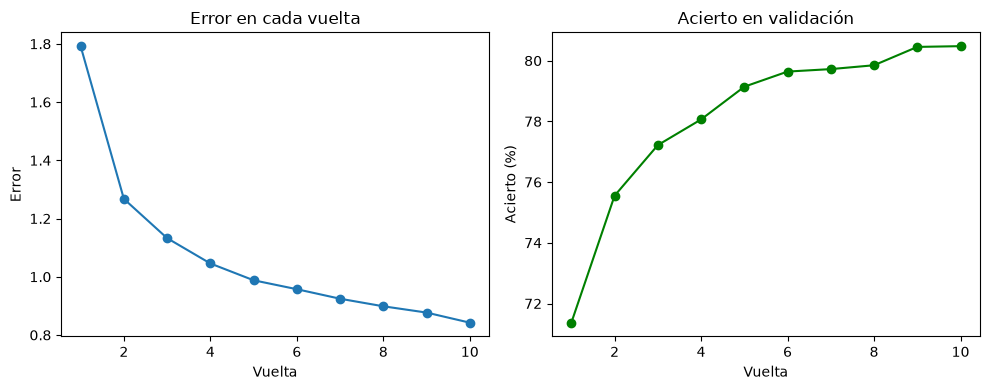

In [26]:
vueltas = range(1, len(historia_acierto) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(vueltas, historia_error, marker="o")
plt.title("Error en cada vuelta")
plt.xlabel("Vuelta")
plt.ylabel("Error")

plt.subplot(1, 2, 2)
plt.plot(vueltas, [a * 100 for a in historia_acierto], marker="o", color="green")
plt.title("Acierto en validación")
plt.xlabel("Vuelta")
plt.ylabel("Acierto (%)")

plt.tight_layout()
plt.show()

### probar la red con las imágenes de prueba

In [27]:
from sklearn.metrics import accuracy_score, precision_score

Xts_t = Xts_t.to(dispositivo)

modelo.eval()
with torch.no_grad():
    pred_prueba = modelo(Xts_t).argmax(1).cpu().numpy()

exactitud = accuracy_score(Yts, pred_prueba)
precision = precision_score(Yts, pred_prueba, average="macro")

p("Exactitud:", round(exactitud, 4))
p("Precisión:", round(precision, 4))

Exactitud: 0.7824
Precisión: 0.8257


### xactitud de la red en cada grupo: dígitos, letras y animales

In [28]:
es_digito = Yts < 10
es_letra = (Yts >= 10) & (Yts < 47)
es_animal = Yts >= 47

tabla_grupos = pd.DataFrame({
    "grupo": ["Dígitos", "Letras", "Animales"],
    "imágenes de prueba": [es_digito.sum(), es_letra.sum(), es_animal.sum()],
    "exactitud": [
        round(accuracy_score(Yts[es_digito], pred_prueba[es_digito]), 4),
        round(accuracy_score(Yts[es_letra], pred_prueba[es_letra]), 4),
        round(accuracy_score(Yts[es_animal], pred_prueba[es_animal]), 4)
    ]
})
d(tabla_grupos)

,grupo,imágenes de prueba,exactitud
0,Dígitos,10000,0.9782
1,Letras,14800,0.8627
2,Animales,24000,0.6513


### ver las confusiones más frecuentes 

In [29]:
confusiones = pd.DataFrame({
    "real": [clases[k] for k in Yts],
    "dijo la red": [clases[k] for k in pred_prueba]
})
confusiones = confusiones[confusiones["real"] != confusiones["dijo la red"]]

d(confusiones.value_counts().head(15).rename("veces").reset_index())

,real,dijo la red,veces
0,pájaro,pato,249
1,perro,caballo,248
2,elefante,rana,245
3,pato,pájaro,234
4,g,q,205
5,gato,cerdo,192
6,perro,rana,190
7,vaca,caballo,179
8,cangrejo,araña,167
9,perro,vaca,166


### guardar la red 

In [30]:
Carpeta_modelos = Carpeta_Proyecto / "modelos"
torch.save(modelo.state_dict(), Carpeta_modelos / "red_completa.pt")
p("Red guardada en:", Carpeta_modelos / "red_completa.pt")

Red guardada en: /home/Ian/prediccion_red/modelos/red_completa.pt


### guardar los nombres de las 67 clases para el servidor

In [31]:
grupos = ["dígito"] * len(clases_digitos) + ["letra"] * len(clases_letras) + ["animal"] * len(clases_animales)

tabla_clases = pd.DataFrame({"clase": clases, "grupo": grupos})
tabla_clases.to_csv(Carpeta_modelos / "clases_red_completa.csv", index=False)

p("Clases guardadas:", len(tabla_clases))
d(tabla_clases.head(12))

Clases guardadas: 67


,clase,grupo
0,0,dígito
1,1,dígito
2,2,dígito
3,3,dígito
4,4,dígito
5,5,dígito
6,6,dígito
7,7,dígito
8,8,dígito
9,9,dígito
